
<div align="center">

<img src="https://capsule-render.vercel.app/api?type=waving&color=0:050B18,50:0B3D91,100:123B60&height=190&section=header&text=Luis%20Barahona&fontSize=42&fontColor=FFFFFF&fontAlignY=38&desc=DATA%20ENGINEERING%20%7C%20ARTIFICIAL%20INTELLIGENCE%20%7C%20DEVELOPER&descAlignY=62&descSize=14" width="50%" alt="Luis Barahona - Data Engineering and AI">

<img src="https://readme-typing-svg.demolab.com?font=Fira+Code&weight=500&size=17&duration=3500&pause=1200&color=38BDF8&center=true&vCenter=true&width=600&lines=Python+%7C+SQL+%7C+Data+Engineering;Artificial+Intelligence+%7C+Machine+Learning;Data+Science+%7C+Cloud+Computing;Building+Technology+for+the+Future" alt="Technical expertise">

</div>

---
<div align="center">
### Professional Profile

I am a Mexican Data Engineer and a 2026 graduate of Universidad del Caribe, passionate about technology, innovation, and continuous learning.
Beyond technical expertise, I value communication, teamwork, collaboration, and building meaningful connections with others. I believe that every person offers an opportunity to learn something new, and I am always motivated to share knowledge, explore new ideas, and grow both personally and professionally.

---

<div align="center">

<img src="https://skillicons.dev/icons?i=python,mysql,postgres,git,github,react,firebase,linux,docker,vscode&theme=dark" alt="Technical skills">


<strong>Data Engineering ·  Data Analytics · Data science · Artificial Intelligence · Machine Learning · Data Analytics · Developer</strong>

</div>

---
<div align="center">

| Platform | Contact |
|:---|:---|
| Email | [190300395@ucaribe.edu.mx](mailto:190300395@ucaribe.edu.mx) |
| GitHub | [github.com/LuisBarahonaMX](https://github.com/LuisBarahonaMX) |
| LinkedIn | [linkedin.com/in/luis-barahona-mx](https://www.linkedin.com/in/luis-barahona-mx/) |
| Instagram | [@luisbarahonamx](https://www.instagram.com/luisbarahonamx/) |
| X | [@luisbarahonaMX](https://x.com/luisbarahonaMX) |
| Website | [SIKO AI Platform](https://sikoai.web.app/) |
</div>



# Redes Neuronales SOM | Aprendizaje No Supervisado y Optimización de Hiperparámetros

### Laboratorio de aprendizaje estadístico con datos RGB en Python

**Descripción:** Este notebook implementa un **mapa autoorganizado (Self-Organizing Map, SOM)** para organizar patrones de colores RGB mediante aprendizaje no supervisado. Se generan **3,000 observaciones sintéticas** de tres componentes (rojo, verde y azul) y se utiliza una cuadrícula de **10 × 10 neuronas**. Se estudian la neurona ganadora (*Best Matching Unit*, BMU), la actualización de pesos, la evolución por épocas y el impacto de la tasa de aprendizaje y el radio de vecindad.

**Objetivo:** comprender experimentalmente el entrenamiento de una red SOM y comparar distintas configuraciones mediante visualizaciones y un indicador de error de cuantización.

**Tecnologías:** Python · NumPy · Matplotlib · Google Colab / Jupyter Notebook

**Autor:** Data Engineer Luis Barahona · [GitHub](https://github.com/LuisBarahonaMX)

> **Alcance:** los datos RGB son sintéticos. Este laboratorio muestra aprendizaje no supervisado y organización de colores; no es una clasificación supervisada ni utiliza imágenes reales.

## 1. Bibliotecas y configuración
Se importan NumPy y Matplotlib, se fija una semilla para reproducir la generación de datos y se establece la configuración inicial de la cuadrícula.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 0
m, n = 10, 10
n_x = 3000
print(f"Cuadrícula SOM: {m} × {n} | Neuronas: {m*n} | Muestras: {n_x}")

Cuadrícula SOM: 10 × 10 | Neuronas: 100 | Muestras: 3000


## 2. Decaimiento de la tasa de aprendizaje
Se visualizan cuatro tasas de decaimiento exponencial. Una reducción más rápida hace que las actualizaciones de pesos pierdan intensidad antes; los valores mostrados son ilustrativos.

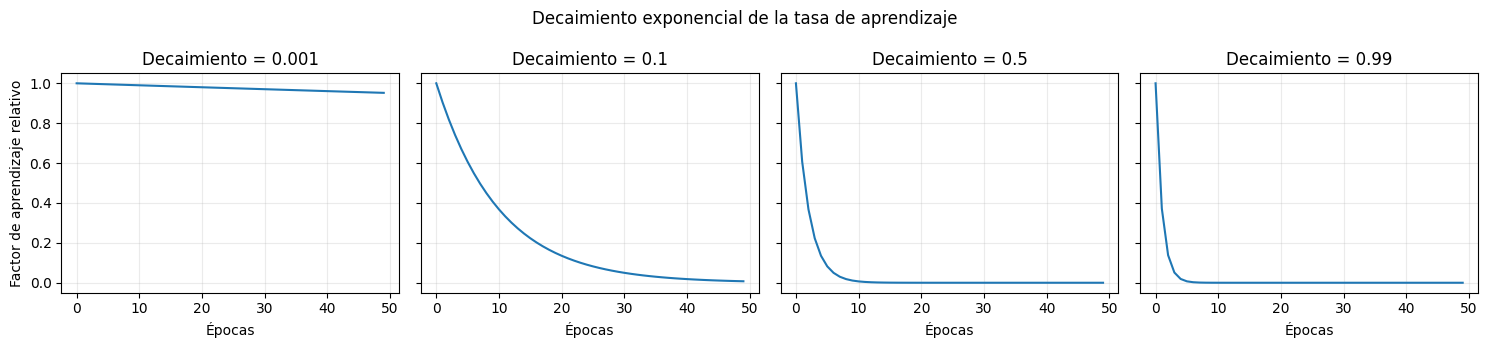

In [ ]:
epochs_axis = np.arange(0, 50)
learning_rate_decays = [0.001, 0.1, 0.5, 0.99]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5), sharey=True)
for ax, decay in zip(axes, learning_rate_decays):
    ax.plot(epochs_axis, np.exp(-epochs_axis * decay), color='tab:blue')
    ax.set_title(f'Decaimiento = {decay}')
    ax.set_xlabel('Épocas')
    ax.grid(alpha=0.25)
axes[0].set_ylabel('Factor de aprendizaje relativo')
fig.suptitle('Decaimiento exponencial de la tasa de aprendizaje')
plt.tight_layout()
plt.show()

## 3. Identificación de la neurona ganadora (BMU)
La BMU es la neurona cuyos pesos tienen la menor distancia euclidiana a una muestra RGB. Esta función encuentra su posición dentro del mapa.

In [ ]:
def find_BMU(SOM, x):
    """Devuelve (fila, columna) de la neurona más cercana a x."""
    dist_sq = np.square(SOM - x).sum(axis=2)
    return np.unravel_index(np.argmin(dist_sq), dist_sq.shape)

## 4. Actualización de pesos y vecindad
Se ajustan la neurona ganadora y las neuronas cercanas con una influencia gaussiana. Si el radio es casi cero, se actualiza únicamente la BMU.

In [ ]:
def update_weights(SOM, train_ex, learn_rate, radius_sq, BMU_coord, step=3):
    """Actualiza la BMU y una vecindad local con influencia gaussiana."""
    g, h = BMU_coord
    if radius_sq < 1e-3:
        SOM[g, h, :] += learn_rate * (train_ex - SOM[g, h, :])
        return SOM
    r0, r1 = max(0, g - step), min(SOM.shape[0], g + step + 1)
    c0, c1 = max(0, h - step), min(SOM.shape[1], h + step + 1)
    rr, cc = np.mgrid[r0:r1, c0:c1]
    dist_sq = (rr - g)**2 + (cc - h)**2
    influence = np.exp(-dist_sq / (2.0 * radius_sq))[:, :, None]
    SOM[r0:r1, c0:c1] += learn_rate * influence * (train_ex - SOM[r0:r1, c0:c1])
    return SOM

## 5. Entrenamiento de la red SOM
La rutina procesa las muestras en orden aleatorio en cada época y reduce la tasa de aprendizaje y el radio con una función exponencial. Se utiliza un generador independiente para que los ensayos sean reproducibles.

In [ ]:
def train_SOM(SOM, train_data, learn_rate=0.1, radius_sq=1.0,
              lr_decay=0.1, radius_decay=0.1, epochs=10, seed=SEED):
    """Entrena SOM sin modificar el conjunto de entrenamiento de entrada."""
    if epochs < 1 or learn_rate <= 0 or radius_sq <= 0:
        raise ValueError('epochs debe ser >= 1 y learn_rate/radius_sq deben ser positivos')
    rng = np.random.default_rng(seed)
    for epoch in range(epochs):
        current_lr = learn_rate * np.exp(-epoch * lr_decay)
        current_radius_sq = radius_sq * np.exp(-epoch * radius_decay)
        for index in rng.permutation(len(train_data)):
            example = train_data[index]
            bmu = find_BMU(SOM, example)
            update_weights(SOM, example, current_lr, current_radius_sq, bmu)
    return SOM

## 6. Generación de muestras RGB e inicialización
Se crean 3,000 colores sintéticos mediante una semilla fija. Los pesos iniciales de las 100 neuronas se generan dentro del mismo rango de intensidad RGB (0–255). Se muestra el conjunto y el estado inicial del mapa.

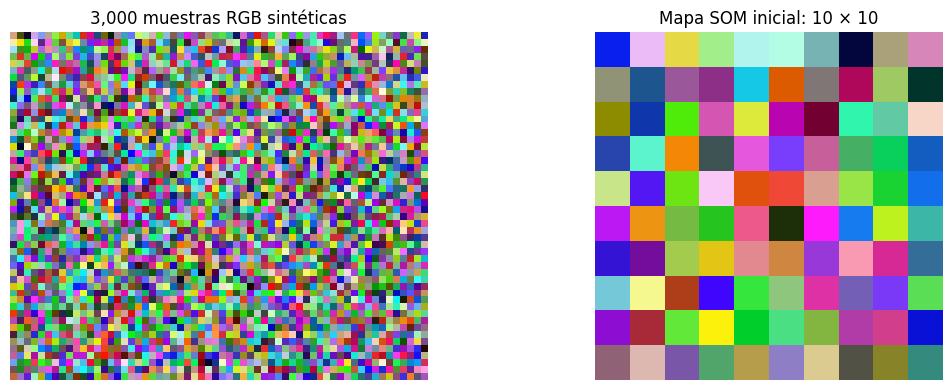

In [ ]:
rng = np.random.default_rng(SEED)
train_data = rng.integers(0, 256, size=(n_x, 3)).astype(float)
SOM_initial = rng.integers(0, 256, size=(m, n, 3)).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(train_data.astype(np.uint8).reshape(50, 60, 3))
axes[0].set_title('3,000 muestras RGB sintéticas')
axes[1].imshow(SOM_initial.astype(np.uint8))
axes[1].set_title('Mapa SOM inicial: 10 × 10')
for ax in axes: ax.axis('off')
plt.tight_layout()
plt.show()

## 7. Evaluación del error de cuantización
Se agrega una métrica que faltaba en la práctica original: el **error de cuantización promedio**, que mide la distancia euclidiana media entre cada muestra y su BMU. Un valor menor indica mejor representación de los datos por los prototipos del mapa, pero no garantiza una mejor organización topológica.

In [ ]:
def quantization_error(SOM, data, batch_size=500):
    """Distancia euclidiana media al prototipo más próximo (BMU)."""
    weights = SOM.reshape(-1, SOM.shape[-1])
    total_distance = 0.0
    for start in range(0, len(data), batch_size):
        batch = data[start:start+batch_size]
        distances = np.linalg.norm(batch[:, None, :] - weights[None, :, :], axis=2)
        total_distance += distances.min(axis=1).sum()
    return float(total_distance / len(data))

initial_error = quantization_error(SOM_initial, train_data)
print(f'Error de cuantización inicial: {initial_error:.4f}')

Error de cuantización inicial: 32.6528


## 8. Evolución del mapa según el número de épocas
Se entrena el mapa de forma acumulativa durante **1, 5, 10 y 20 épocas**, manteniendo un historial de estados para comparar los patrones de colores resultantes. Se calcula el error de cuantización en cada etapa.

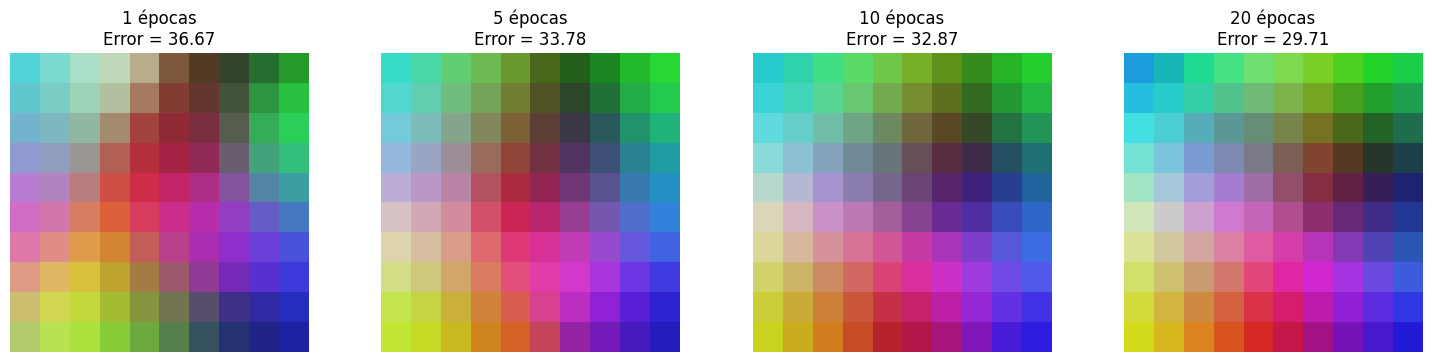

In [ ]:
epoch_targets = [1, 5, 10, 20]
SOM_evolution = SOM_initial.copy()
errors_evolution = []
fig, axes = plt.subplots(1, len(epoch_targets), figsize=(15, 3.6))
prev_epoch = 0
for ax, target in zip(axes, epoch_targets):
    delta = target - prev_epoch
    SOM_evolution = train_SOM(SOM_evolution, train_data, epochs=delta, seed=SEED+target)
    qe = quantization_error(SOM_evolution, train_data)
    errors_evolution.append(qe)
    ax.imshow(np.clip(SOM_evolution, 0, 255).astype(np.uint8))
    ax.set_title(f'{target} épocas\nError = {qe:.2f}')
    ax.axis('off')
    prev_epoch = target
plt.tight_layout()
plt.show()

## 9. Comparación de hiperparámetros
Se prueban nueve combinaciones de tasa de aprendizaje (`η`) y radio de vecindad (`σ²`), cada una con **el mismo estado inicial, las mismas muestras y 5 épocas**. Así es posible comparar visualmente su efecto sin alterar los datos iniciales entre experimentos.

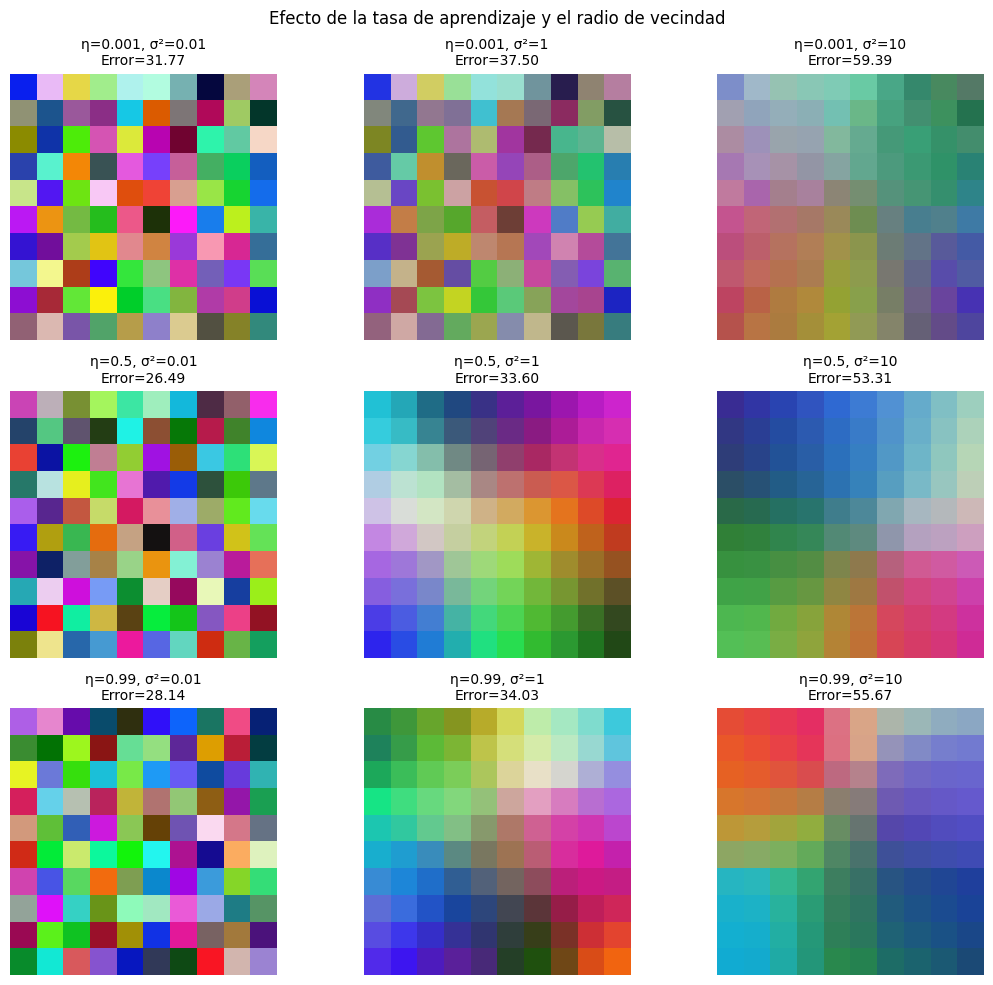

In [ ]:
learning_rates = [0.001, 0.5, 0.99]
radii_sq = [0.01, 1, 10]
results = []
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for i, lr in enumerate(learning_rates):
    for j, radius_sq in enumerate(radii_sq):
        fitted = train_SOM(SOM_initial.copy(), train_data, epochs=5,
                           learn_rate=lr, radius_sq=radius_sq, seed=SEED)
        error = quantization_error(fitted, train_data)
        results.append((lr, radius_sq, error))
        axes[i, j].imshow(np.clip(fitted, 0, 255).astype(np.uint8))
        axes[i, j].set_title(f'η={lr}, σ²={radius_sq}\nError={error:.2f}', fontsize=10)
        axes[i, j].axis('off')
fig.suptitle('Efecto de la tasa de aprendizaje y el radio de vecindad')
plt.tight_layout()
plt.show()

## 10. Resultados comparativos
Se muestran las configuraciones ordenadas por error de cuantización. La comparación corresponde a **datos de entrenamiento sintéticos**; por ello, los resultados son ilustrativos y no deben interpretarse como desempeño sobre datos reales desconocidos.

    Tasa η     Radio σ²     Error promedio
--------------------------------------------
     0.500         0.01            26.4861
     0.990         0.01            28.1367
     0.001         0.01            31.7689
     0.500         1.00            33.5980
     0.990         1.00            34.0300
     0.001         1.00            37.5005
     0.500        10.00            53.3120
     0.990        10.00            55.6669
     0.001        10.00            59.3865


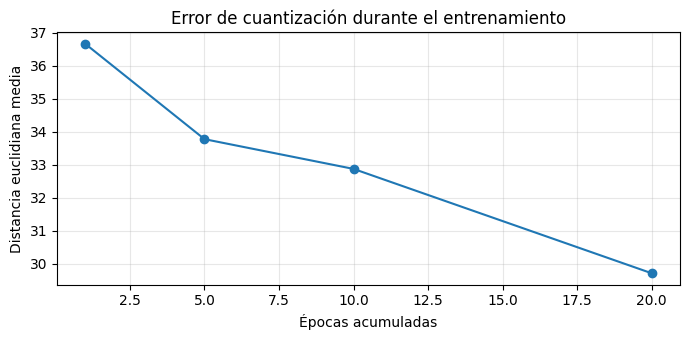

Menor error observado entre las 9 pruebas: η=0.5, σ²=0.01, error=26.4861


In [ ]:
print(f'{"Tasa η":>10} {"Radio σ²":>12} {"Error promedio":>18}')
print('-' * 44)
for lr, radius_sq, error in sorted(results, key=lambda item: item[2]):
    print(f'{lr:>10.3f} {radius_sq:>12.2f} {error:>18.4f}')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(epoch_targets, errors_evolution, marker='o')
ax.set_title('Error de cuantización durante el entrenamiento')
ax.set_xlabel('Épocas acumuladas')
ax.set_ylabel('Distancia euclidiana media')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_lr, best_radius, best_error = min(results, key=lambda item: item[2])
print(f'Menor error observado entre las 9 pruebas: η={best_lr}, σ²={best_radius}, error={best_error:.4f}')

## Conclusiones

Este laboratorio muestra cómo una **red SOM organiza colores RGB mediante aprendizaje no supervisado**. La BMU identifica el prototipo más cercano y la función de vecindad modifica los pesos para producir una distribución visual de colores.

Se añadieron un entrenamiento reproducible, una comparación justa de nueve combinaciones de hiperparámetros y un indicador cuantitativo (**error de cuantización**) para complementar las gráficas. Los valores numéricos se obtienen al ejecutar el notebook; no se presupone qué configuración será mejor.

**Limitaciones:** el ejemplo usa datos RGB aleatorios; un menor error de cuantización no significa automáticamente mejor preservación de vecindades, generalización ni aptitud para clasificar imágenes. Para avanzar, se podrían evaluar errores topológicos y utilizar conjuntos de datos reales.

---
**Autor:** Data Engineer Luis Barahona  
**GitHub:** [LuisBarahonaMX](https://github.com/LuisBarahonaMX)